In [1]:
%matplotlib inline
#matplotlib magic指令

import matplotlib
import matplotlib.pyplot as plt
from IPython import display
plt.rcParams.update({'font.size': 6})


# Simpsons Unlimited! 無限辛普森

To install trident, please cancel the syntax comment below.
安裝trident請取消下方語法註解

In [2]:
#!pip install tridentx 

引用相關軟體包，在此我們是透過環境變數TRIDENT_BACKEND='pytorch'來指定後台框架。

In [3]:
import os
os.environ['TRIDENT_BACKEND'] = 'pytorch'
#!pip install tridentx --upgrade
import trident as T
from trident import *
from trident import context
from trident.models.pytorch_gan import gan_builder
from trident.optims.trainers import GanTrainingPlan

trident 0.7.4.2


Using Pytorch backend.
Image Data Format: channels_first.
Image Channel Order: rgb.
Pytorch version:1.11.0+cu113.
Automatic Mixed Precision Support:True.


Opencv version:4.5.4-dev.
Pillow version:8.4.0.


## Preparation for data.準備數據 

In [4]:
#載入simpsons數據
data_provider=load_examples_data("simpsons")
print(data_provider.signature)

archive file is already existing, donnot need download again.
extraction is finished, donnot need extract again.
C:/Users/allan/.trident/datasets/examples_simpsons/simpsons
get simpsons images :9876


In [5]:
d

#加入數據增強
data_provider.image_transform_funcs=[
    OneOf(
        [Resize((64,64),True)],
        [Resize((72,72),True),
        RandomCrop((64,64))]
    ),
    RandomLighting(value_range=(0,0.8)),
    RandomAdjustGamma(gamma_range=(0.8,1.2)),
    RandomAdjustSaturation(scale=(0.8, 1.2)),
    RandomAdjustContrast(scale=(0.8 ,1.2)),
    Normalize(127.5,127.5)
]






data_provider( ) -> image: Tensor[(None, 200, 200, 3)] (ObjectType.rgb), noise: Tensor[(100,)] (ObjectType.random_noise) 


We can use the preview_images command of the data provider to see what the data-enhanced image looks like .
我們可以利用資料提供者的preview_images指令來檢視數據增強後的圖片的樣子

image


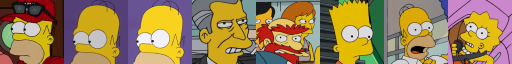

In [6]:
data_provider.preview_images()

In [7]:
_data,_noise=data_provider.next()
print(_data.shape)

(8, 3, 64, 64)


## Design network. 設計網路結構

In [8]:
#建構生成器以及鑑別器
generator, discriminator=gan_builder(noise_shape=100,input_shape=(3,64,64), generated_output_shape=(3,64,64), 
                upsample_mode= 'pixel_shuffle', generator_build_block='bottleneck', discriminator_build_block='resnet', 
                generator_network_type='decoder', discriminator_network_type='encoder',use_skip_connections=False,
                generator_use_spectral=True, discriminator_use_spectral=True, activation='leaky_relu', generator_norm='instance', discriminator_norm='batch',
                use_dilation=False, use_dropout=True, use_self_attention=False, use_minibatch_discrimination=False)


In [9]:
generator.with_optimizer(optimizer=Adam,lr=2e-4,betas=(0.5, 0.999),gradient_centalization='all')\
    .with_regularizer('l2') \
    .with_grad_clipping(3)\
    .with_automatic_mixed_precision_training()


Automatic Mixed Precision:Turn On.


Model(
  (_regs): <function l2_reg at 0x000001DDC20F2840>
)

In [10]:
discriminator.with_optimizer(optimizer=Adam,lr=5e-4,betas=(0.9, 0.999),gradient_centalization='all') \
    .with_regularizer('l2')\
    .with_grad_clipping(3)\
    .with_automatic_mixed_precision_training()


Automatic Mixed Precision:Turn On.


ImageClassificationModel(
  (_regs): <function l2_reg at 0x000001DDC20F2840>
)

## Design TrainingPlan 設計學習計畫

為了能夠更簡單的訓練出穩定的GAN，因此trident特別設計了專門訓練GAN用的GanTrainingPlan。

In [11]:

plan=GanTrainingPlan()\
    .with_generator(generator)\
    .with_discriminator(discriminator)\
    .with_data_loader(data_provider)\
    .repeat_epochs(50)\
    .with_batch_size(32)\
    .with_gan_type('lsgan')\
    .with_noised_real_images(max_noise_intensity=0.15,decay=3000)\
    .with_feature_matching(loss_weight=0.5,start_epoch=10)\
    .with_label_flipping()\
    .with_total_variation_loss(start_epoch=10)\
    .with_ttur(multiplier=2.5)\
    .print_gpu_utilization(frequency=100,unit='batch')\
    .print_progress_scheduling(10, unit='batch') \
    .display_loss_metric_curve_scheduling(frequency=100, unit='batch', imshow=True) \
    .print_gradients_scheduling(100) \
    .save_model_scheduling(50, unit='batch')




g_loss( d_fake: Tensor[None] , real_label: Tensor[None] ) -> output: Tensor[(None,)]  
real_loss( d_real: Tensor[None] , real_label: Tensor[None] ) -> output: Tensor[(None,)]  
fake_loss( d_fake: Tensor[None] , fake_label: Tensor[None] ) -> output: Tensor[(None,)]  
d_fake( d_fake: Tensor[None] ) -> output: Tensor[(None,)]  
d_fake( d_fake: Tensor[None] ) -> output: Tensor[(None,)]  
d_real( d_real: Tensor[None] ) -> output: Tensor[(None,)]  
feature_matching( real_features: Tensor[None] , fake_features: Tensor[None] ) -> output: Tensor[(None,)]  



在開始執行前，我們可以利用Summary指令來檢視模型結構，其中因為我們指定的是LSGAN，為了讓他能夠更好的收斂，因此trident自動拿掉了鑑別器最後的sigmoid。

In [12]:
generator.summary()

--------------------------------------------------------------------------------------------------------------------------------
                    Layer (type)                      Output Shape               Weight                             Bias      Param #   FLOPS #                  
0.module  [Dense]                                     [None, 4096]               'weight_u', [4096]                 'bias', [4096]  417,892  835,780  
                                                                                               'weight_v', [100]                                  
                                                                                               'weight_bar', [4096, 100]                          
0  [SpectralNorm]                                     [None, 4096]                                                            0  0  
1  [BatchNorm]                                        [None, 4096]               'weight', [4096]                   'bias', [4096] 

Model(
  (_losses): <function GanTrainingPlan.with_gan_type.<locals>.g_loss at 0x000001DDCA4DE598>
  (_losses): <function GanTrainingPlan.with_feature_matching.<locals>.feature_matching at 0x000001DDCA4DED08>
  (_metrics): <function GanTrainingPlan.with_gan_type.<locals>.metric_dfake at 0x000001DDA0A347B8>
  (loss_weights): 1.0
  (loss_weights): 0.5
  (_regs): <function l2_reg at 0x000001DDC20F2840>
)

In [13]:
discriminator.summary()

--------------------------------------------------------------------------------------------------------------------------------
              Layer (type)               Output Shape               Weight                              Bias      Param #   FLOPS #                  
0  [Conv2d]                              [None, 32, 64, 64]         'weight', [32, 3, 5, 5]                       2,400  19,656,704  
1.conv.module  [Conv2d]                  [None, 64, 32, 32]         'weight_u', [64]                              18,784  38,466,560  
                                                                                        'weight_v', [288]                                   
                                                                                        'weight_bar', [64, 32, 3, 3]                        
1.conv  [SpectralNorm]                   [None, 64, 32, 32]                                                       0  0  
1.norm  [BatchNorm]                      [None, 6

ImageClassificationModel(
  (_losses): <function GanTrainingPlan.with_gan_type.<locals>.real_loss at 0x000001DDC97E1AE8>
  (_losses): <function GanTrainingPlan.with_gan_type.<locals>.fake_loss at 0x000001DDCA4DE840>
  (_metrics): <function GanTrainingPlan.with_gan_type.<locals>.metric_dfake at 0x000001DDA0A347B8>
  (_metrics): <function GanTrainingPlan.with_gan_type.<locals>.metric_dreal at 0x000001DDA0A34840>
  (loss_weights): 0.5
  (loss_weights): 0.5
  (_regs): <function l2_reg at 0x000001DDC20F2840>
)

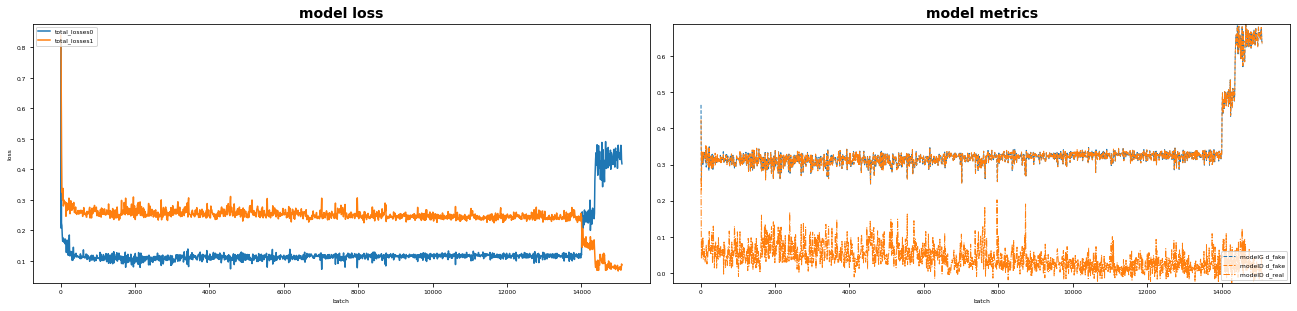

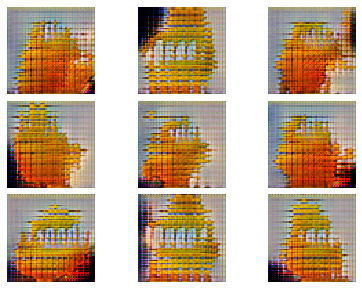

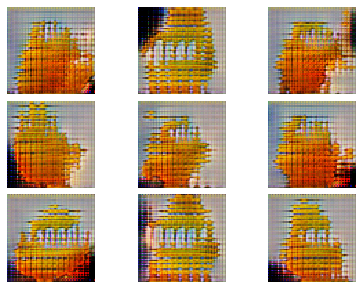

[0]  NVIDIA GeForce GTX 1660 Ti with Max-Q Design |   59°C   2% | 1724 /6144.0 MB  28.06%
[0]  NVIDIA GeForce GTX 1660 Ti with Max-Q Design |   59°C   2% | 1724 /6144.0 MB  28.06%
modelG          last_layer gradients: 7.624e-03 

modelD          first_layer gradients: 1.928e-03 |last_layer gradients: 1.538e-03 

modelG  Step: 589ms    | Loss: 0.474 | d_fake: 67.600%  | lr: 2.000e-04  | epoch: 48  ( 271/309 )
modelD  Step: 349ms    | Loss: 0.072 | d_fake: 66.962% , d_real: 0.0261  | lr: 5.000e-04  | epoch: 48  ( 271/309 )
 



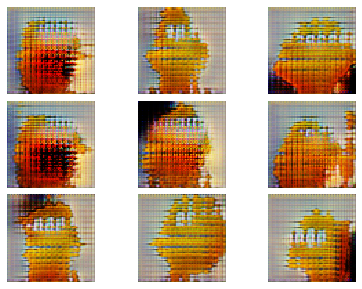

modelG  Step: 564ms    | Loss: 0.422 | d_fake: 63.690%  | lr: 2.000e-04  | epoch: 48  ( 281/309 )
modelD  Step: 385ms    | Loss: 0.077 | d_fake: 64.119% , d_real: 0.0073  | lr: 5.000e-04  | epoch: 48  ( 281/309 )
 



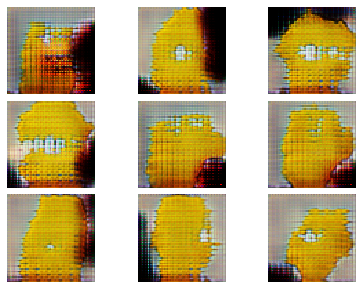

modelG  Step: 601ms    | Loss: 0.469 | d_fake: 67.166%  | lr: 2.000e-04  | epoch: 48  ( 291/309 )
modelD  Step: 414ms    | Loss: 0.074 | d_fake: 67.471% , d_real: 0.0338  | lr: 5.000e-04  | epoch: 48  ( 291/309 )
 



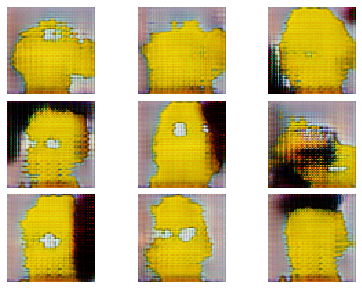

modelG  Step: 601ms    | Loss: 0.416 | d_fake: 63.160%  | lr: 2.000e-04  | epoch: 48  ( 301/309 )
modelD  Step: 412ms    | Loss: 0.083 | d_fake: 63.173% , d_real: 0.0128  | lr: 5.000e-04  | epoch: 48  ( 301/309 )
 



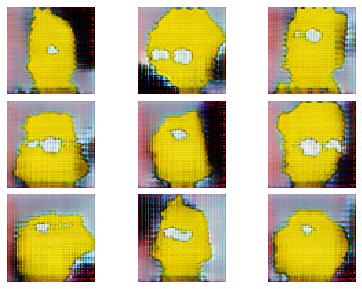

{ g_loss: 0.423, l2_reg_Loss: 0.006, total_losses: 0.435, feature_matching: 0.001, total_variation_norm_reg_Loss: 0.004 }
{ real_loss: 0.005, fake_loss: 0.061, l2_reg_Loss: 0.003, total_losses: 0.070 }
 



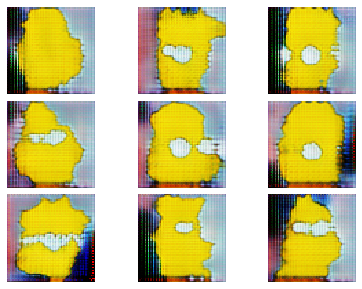

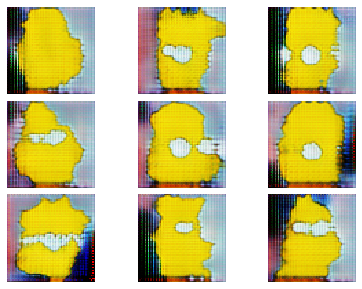

modelG  Step: 1s2ms    | Loss: 0.429 | d_fake: 63.115%  | lr: 2.000e-04  | epoch: 49  ( 11/309 )
modelD  Step: 643ms    | Loss: 0.077 | d_fake: 63.160% , d_real: -0.0010  | lr: 5.000e-04  | epoch: 49  ( 11/309 )
 



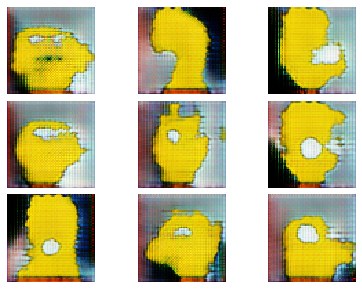

modelG  Step: 509ms    | Loss: 0.501 | d_fake: 69.565%  | lr: 2.000e-04  | epoch: 49  ( 21/309 )
modelD  Step: 351ms    | Loss: 0.074 | d_fake: 69.515% , d_real: 0.0388  | lr: 5.000e-04  | epoch: 49  ( 21/309 )
 



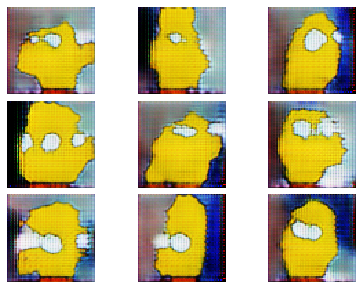

modelG  Step: 538ms    | Loss: 0.413 | d_fake: 63.081%  | lr: 2.000e-04  | epoch: 49  ( 31/309 )
modelD  Step: 371ms    | Loss: 0.088 | d_fake: 62.857% , d_real: -0.0044  | lr: 5.000e-04  | epoch: 49  ( 31/309 )
 



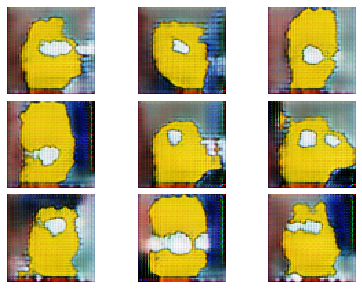

modelG  Step: 554ms    | Loss: 0.456 | d_fake: 66.504%  | lr: 2.000e-04  | epoch: 49  ( 41/309 )
modelD  Step: 413ms    | Loss: 0.078 | d_fake: 66.485% , d_real: 0.0130  | lr: 5.000e-04  | epoch: 49  ( 41/309 )
 



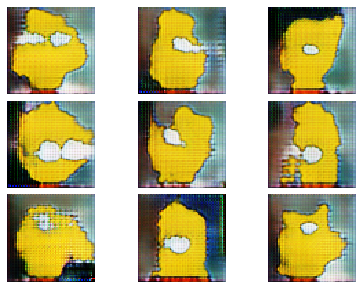

modelG  Step: 531ms    | Loss: 0.445 | d_fake: 65.710%  | lr: 2.000e-04  | epoch: 49  ( 51/309 )
modelD  Step: 362ms    | Loss: 0.071 | d_fake: 65.658% , d_real: 0.0181  | lr: 5.000e-04  | epoch: 49  ( 51/309 )
 



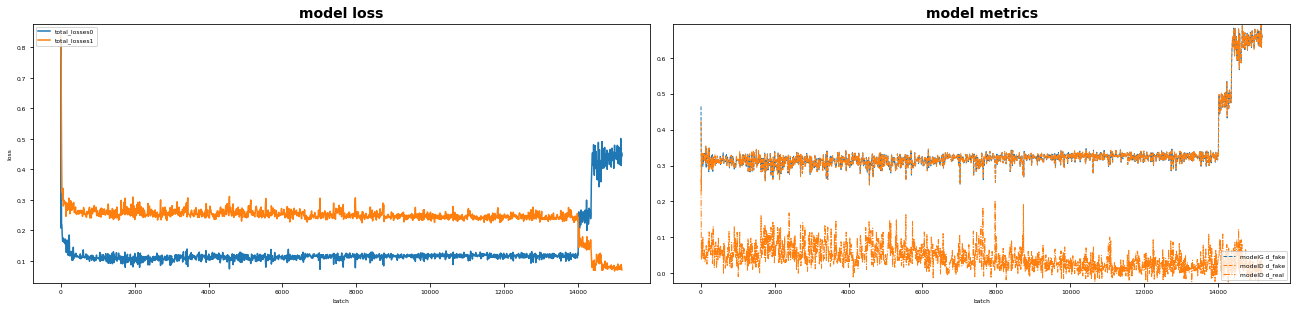

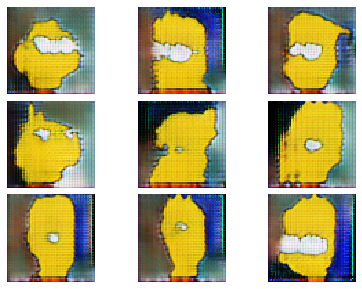

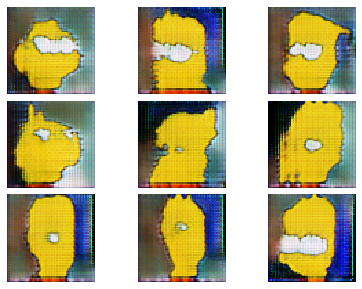

[0]  NVIDIA GeForce GTX 1660 Ti with Max-Q Design |   58°C   3% | 1724 /6144.0 MB  28.06%
[0]  NVIDIA GeForce GTX 1660 Ti with Max-Q Design |   58°C   3% | 1724 /6144.0 MB  28.06%
modelG          last_layer gradients: 7.624e-03 

modelD          first_layer gradients: 6.172e-04 |last_layer gradients: 1.137e-03 

modelG  Step: 635ms    | Loss: 0.440 | d_fake: 65.316%  | lr: 2.000e-04  | epoch: 49  ( 61/309 )
modelD  Step: 372ms    | Loss: 0.075 | d_fake: 65.641% , d_real: 0.0102  | lr: 5.000e-04  | epoch: 49  ( 61/309 )
 



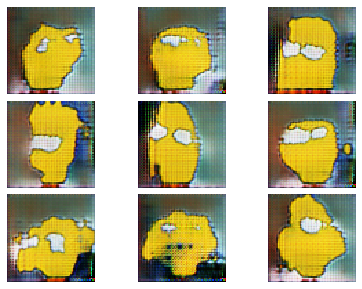

modelG  Step: 967ms    | Loss: 0.465 | d_fake: 67.203%  | lr: 2.000e-04  | epoch: 49  ( 71/309 )
modelD  Step: 549ms    | Loss: 0.075 | d_fake: 67.336% , d_real: 0.0220  | lr: 5.000e-04  | epoch: 49  ( 71/309 )
 



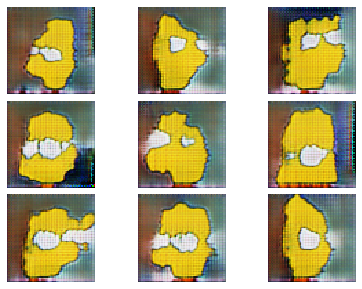

modelG  Step: 703ms    | Loss: 0.430 | d_fake: 64.448%  | lr: 2.000e-04  | epoch: 49  ( 81/309 )
modelD  Step: 483ms    | Loss: 0.080 | d_fake: 64.487% , d_real: -0.0003  | lr: 5.000e-04  | epoch: 49  ( 81/309 )
 



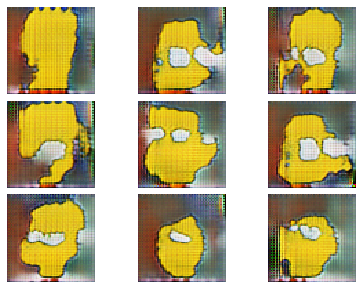

modelG  Step: 561ms    | Loss: 0.456 | d_fake: 66.390%  | lr: 2.000e-04  | epoch: 49  ( 91/309 )
modelD  Step: 397ms    | Loss: 0.072 | d_fake: 66.616% , d_real: -0.0147  | lr: 5.000e-04  | epoch: 49  ( 91/309 )
 



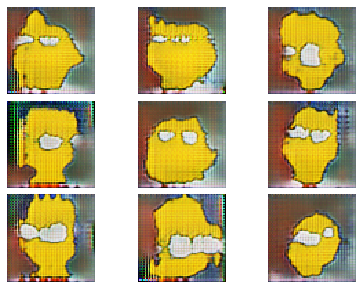

modelG  Step: 878ms    | Loss: 0.438 | d_fake: 65.082%  | lr: 2.000e-04  | epoch: 49  ( 101/309 )
modelD  Step: 597ms    | Loss: 0.081 | d_fake: 64.923% , d_real: 0.0526  | lr: 5.000e-04  | epoch: 49  ( 101/309 )
 



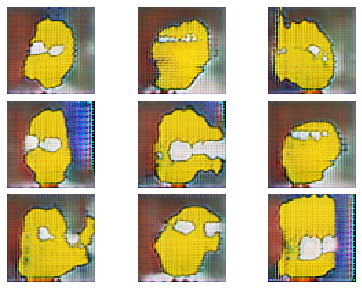

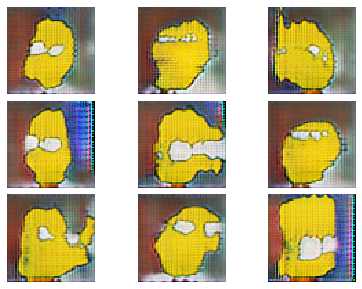

modelG  Step: 937ms    | Loss: 0.415 | d_fake: 63.296%  | lr: 2.000e-04  | epoch: 49  ( 111/309 )
modelD  Step: 498ms    | Loss: 0.085 | d_fake: 63.499% , d_real: -0.0028  | lr: 5.000e-04  | epoch: 49  ( 111/309 )
 



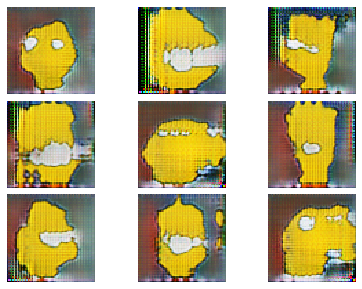

modelG  Step: 858ms    | Loss: 0.491 | d_fake: 69.029%  | lr: 2.000e-04  | epoch: 49  ( 121/309 )
modelD  Step: 734ms    | Loss: 0.063 | d_fake: 69.203% , d_real: 0.0062  | lr: 5.000e-04  | epoch: 49  ( 121/309 )
 



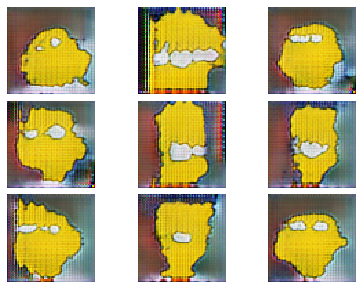

modelG  Step: 592ms    | Loss: 0.416 | d_fake: 63.420%  | lr: 2.000e-04  | epoch: 49  ( 131/309 )
modelD  Step: 404ms    | Loss: 0.081 | d_fake: 62.970% , d_real: 0.0242  | lr: 5.000e-04  | epoch: 49  ( 131/309 )
 



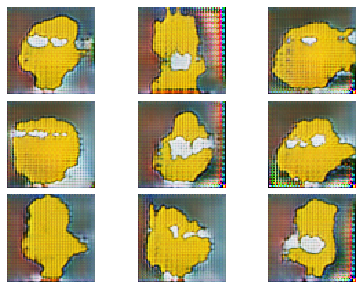

modelG  Step: 555ms    | Loss: 0.448 | d_fake: 65.848%  | lr: 2.000e-04  | epoch: 49  ( 141/309 )
modelD  Step: 383ms    | Loss: 0.075 | d_fake: 65.942% , d_real: 0.0055  | lr: 5.000e-04  | epoch: 49  ( 141/309 )
 



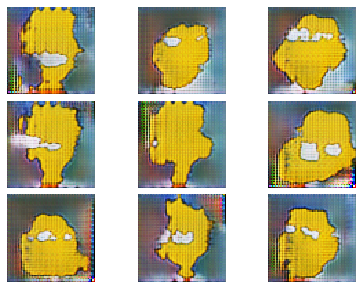

modelG  Step: 504ms    | Loss: 0.443 | d_fake: 65.475%  | lr: 2.000e-04  | epoch: 49  ( 151/309 )
modelD  Step: 376ms    | Loss: 0.076 | d_fake: 65.736% , d_real: 0.0027  | lr: 5.000e-04  | epoch: 49  ( 151/309 )
 



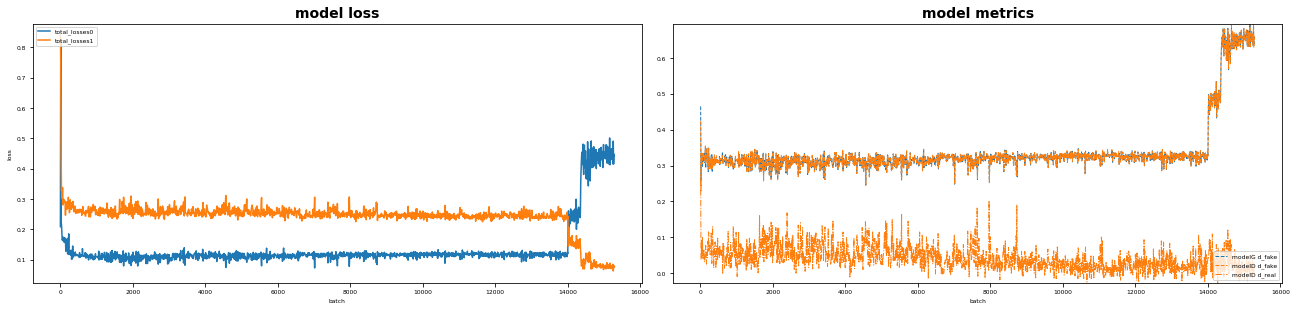

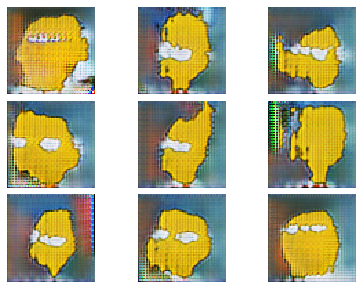

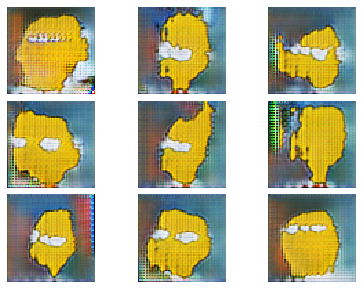

[0]  NVIDIA GeForce GTX 1660 Ti with Max-Q Design |   59°C   9% | 1726 /6144.0 MB  28.09%
[0]  NVIDIA GeForce GTX 1660 Ti with Max-Q Design |   59°C   9% | 1726 /6144.0 MB  28.09%
modelG          last_layer gradients: 7.624e-03 

modelD          first_layer gradients: 1.322e-03 |last_layer gradients: 1.817e-03 

modelG  Step: 574ms    | Loss: 0.447 | d_fake: 65.778%  | lr: 2.000e-04  | epoch: 49  ( 161/309 )
modelD  Step: 345ms    | Loss: 0.071 | d_fake: 65.923% , d_real: 0.0244  | lr: 5.000e-04  | epoch: 49  ( 161/309 )
 



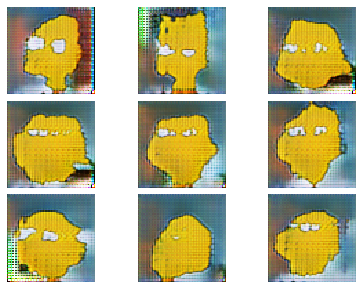

modelG  Step: 539ms    | Loss: 0.481 | d_fake: 68.125%  | lr: 2.000e-04  | epoch: 49  ( 171/309 )
modelD  Step: 374ms    | Loss: 0.073 | d_fake: 68.017% , d_real: 0.0369  | lr: 5.000e-04  | epoch: 49  ( 171/309 )
 



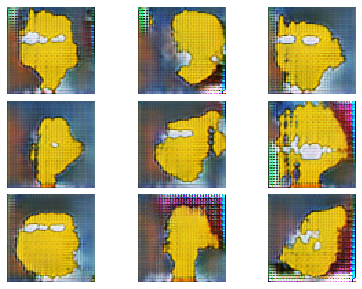

modelG  Step: 532ms    | Loss: 0.422 | d_fake: 63.857%  | lr: 2.000e-04  | epoch: 49  ( 181/309 )
modelD  Step: 386ms    | Loss: 0.088 | d_fake: 63.703% , d_real: -0.0412  | lr: 5.000e-04  | epoch: 49  ( 181/309 )
 



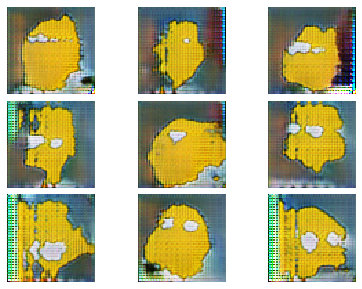

modelG  Step: 506ms    | Loss: 0.448 | d_fake: 65.909%  | lr: 2.000e-04  | epoch: 49  ( 191/309 )
modelD  Step: 363ms    | Loss: 0.077 | d_fake: 65.913% , d_real: 0.0439  | lr: 5.000e-04  | epoch: 49  ( 191/309 )
 



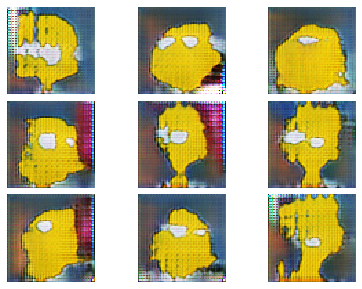

modelG  Step: 515ms    | Loss: 0.419 | d_fake: 63.635%  | lr: 2.000e-04  | epoch: 49  ( 201/309 )
modelD  Step: 345ms    | Loss: 0.083 | d_fake: 63.513% , d_real: 0.0114  | lr: 5.000e-04  | epoch: 49  ( 201/309 )
 



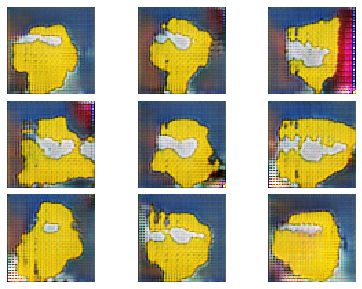

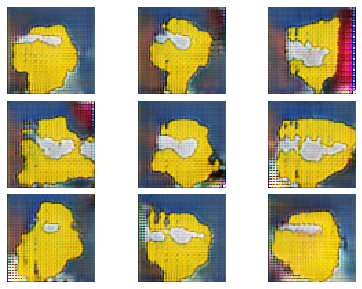

modelG  Step: 575ms    | Loss: 0.448 | d_fake: 65.950%  | lr: 2.000e-04  | epoch: 49  ( 211/309 )
modelD  Step: 336ms    | Loss: 0.070 | d_fake: 66.334% , d_real: 0.0052  | lr: 5.000e-04  | epoch: 49  ( 211/309 )
 



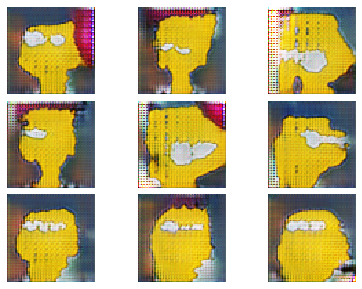

modelG  Step: 576ms    | Loss: 0.440 | d_fake: 65.282%  | lr: 2.000e-04  | epoch: 49  ( 221/309 )
modelD  Step: 422ms    | Loss: 0.079 | d_fake: 65.665% , d_real: 0.0052  | lr: 5.000e-04  | epoch: 49  ( 221/309 )
 



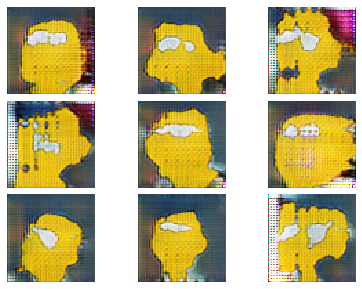

modelG  Step: 610ms    | Loss: 0.468 | d_fake: 67.400%  | lr: 2.000e-04  | epoch: 49  ( 231/309 )
modelD  Step: 449ms    | Loss: 0.072 | d_fake: 67.449% , d_real: 0.0080  | lr: 5.000e-04  | epoch: 49  ( 231/309 )
 



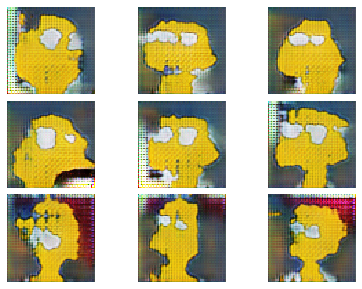

modelG  Step: 474ms    | Loss: 0.443 | d_fake: 65.555%  | lr: 2.000e-04  | epoch: 49  ( 241/309 )
modelD  Step: 315ms    | Loss: 0.072 | d_fake: 65.903% , d_real: 0.0100  | lr: 5.000e-04  | epoch: 49  ( 241/309 )
 



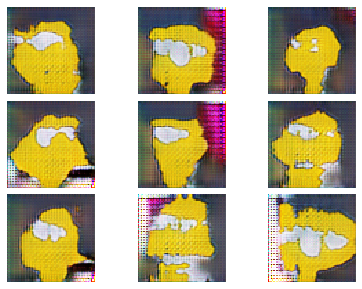

modelG  Step: 481ms    | Loss: 0.432 | d_fake: 64.698%  | lr: 2.000e-04  | epoch: 49  ( 251/309 )
modelD  Step: 340ms    | Loss: 0.079 | d_fake: 64.811% , d_real: 0.0238  | lr: 5.000e-04  | epoch: 49  ( 251/309 )
 



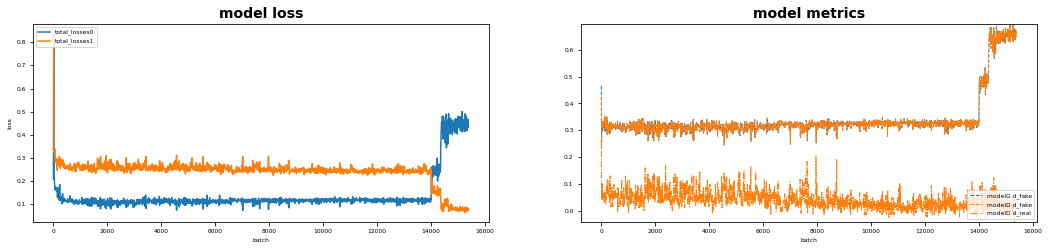

In [14]:
plan.start_now()

Export model output history as GIF
將模型輸出歷程匯出為GIF

In [16]:
from PIL import Image

files = glob.glob("Results/tile_image*.png")
print(len(files),flush=True)
_images = []
for n in tqdm(range(len(files))):
    f=files[n]
    _images.append(Image.open(f).convert('RGB'))

_images[0].save('Results/gan.gif', save_all=True, append_images=_images[1:], optimize=False, duration=2, loop=1)


1914


100%|██████████████████████████████████████████████████████████████████████████████| 1914/1914 [00:25<00:00, 76.49it/s]


Embed GIF in jupyter notebook
將GIF嵌入至jupyter notebook

In [17]:
from IPython.display import HTML
HTML('<img src="Results/gan.gif">')